EDA

In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import RandomOverSampler
from sklearn.svm import SVC, LinearSVC
from sklearn.metrics import classification_report, precision_score, recall_score, f1_score

In [23]:

df_avg = pd.read_csv("avg_river_levels.csv")
df_min = pd.read_csv("min_river_levels.csv")
df_max = pd.read_csv("max_river_levels.csv")
df_locs = pd.read_csv("monitoring_locations.csv")

In [24]:
# Check size

print("Average Levels Shape:", df_avg.shape)
print("Station Locations Shape:", df_locs.shape)

Average Levels Shape: (392, 4382)
Station Locations Shape: (392, 5)


In [25]:
# Inspect the first few rows of the locations and average levels
display(df_locs.head())
display(df_avg.head(2))

,County,Station_Name,Observation_ID,Latitude,Longitude
0,aberdeenshire,"Bogie, Redcraig",aberdeenshire__bogie-redcraig__obs1,57.424758,-2.802015
1,aberdeenshire,"Dee (Grampian), Park",aberdeenshire__dee-grampian-park__obs1,57.075424,-2.335825
2,aberdeenshire,"Dee (Grampian), Polhollick",aberdeenshire__dee-grampian-polhollick__obs1,57.055146,-3.083181
3,aberdeenshire,"Dee (Grampian), Woodend",aberdeenshire__dee-grampian-woodend__obs1,57.050129,-2.603567
4,aberdeenshire,"Dee (Grampian), Mar Lodge",aberdeenshire__dee-grampian-mar-lodge__obs1,56.988040,-3.486198


,County,Station_Name,Observation_ID,05/10/2014,06/10/2014,07/10/2014,08/10/2014,09/10/2014,10/10/2014,13/10/2014,...,29/09/2026,30/09/2026,01/10/2026,02/10/2026,03/10/2026,04/10/2026,05/10/2026,06/10/2026,07/10/2026,08/10/2026
0,aberdeenshire,"Bogie, Redcraig",aberdeenshire__bogie-redcraig__obs1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.133,0.152,0.169,0.143,0.136,0.130,0.126,0.120,0.120,0.120
1,aberdeenshire,"Dee (Grampian), Mar Lodge",aberdeenshire__dee-grampian-mar-lodge__obs1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.721,0.971,0.849,0.799,0.861,0.752,0.727,0.695,0.677,0.669


In [26]:
# Missing entries

# Check how many missing (NaN) days each station has across the 4,382 columns
missing_per_station = df_avg.isna().sum(axis=1)

print(missing_per_station.head())

0    1085
1    1091
2    1087
3    1089
4    1093
dtype: int64


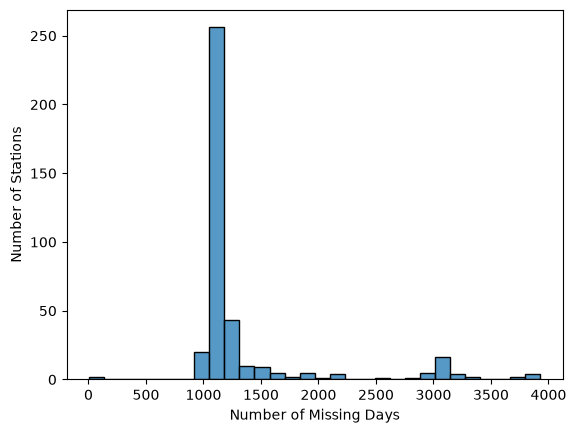

In [27]:
# Plot a histogram of missing data across all stations
sns.histplot(missing_per_station, bins=30)
plt.xlabel("Number of Missing Days")
plt.ylabel("Number of Stations")
plt.show()

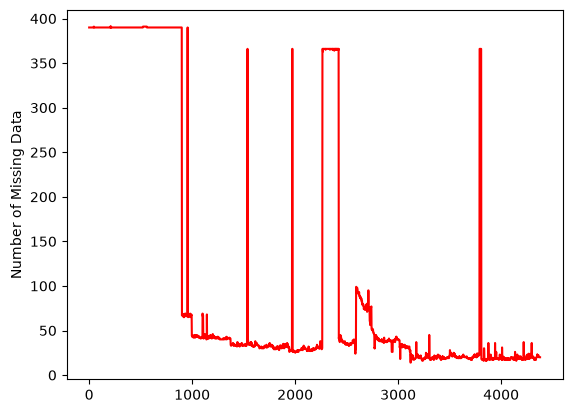

In [28]:
# Count how many stations are missing data on each individual day
# drop first three text columns, only looking at dates
missing_by_date = df_avg.drop(columns=['County', 'Station_Name', 'Observation_ID']).isna().sum()


plt.plot(missing_by_date.values, color='red')
plt.ylabel("Number of Missing Data")
plt.show()

Remove first dates with no data

In [29]:
# Drop dates that do not have at least 300 non-missing values
df_clean = df_avg.dropna(thresh=300, axis=1)

# Check the new shape
print(df_clean.shape)

(392, 3274)


Splitting the data

In [30]:
metadata_cols = ['County', 'Station_Name', 'Observation_ID']
date_cols = [col for col in df_clean.columns if col not in metadata_cols]

# training data first date - end of August 2026
train_dates = [col for col in date_cols if pd.to_datetime(col, format='%d/%m/%Y') <= pd.to_datetime('2026-08-31')]

# testing data: September, October, November 2026
test_dates = [col for col in date_cols if pd.to_datetime(col, format='%d/%m/%Y') >= pd.to_datetime('2026-09-01')]

X_train = df_clean[metadata_cols + train_dates]
X_test = df_clean[metadata_cols + test_dates]

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

Training Data Shape: (392, 3236)
Testing Data Shape: (392, 41)


In [31]:
# Check if there is still any missing values

print("Total missing values in Training Data:", X_train.isna().sum().sum())
print("Total missing values in Testing Data:", X_test.isna().sum().sum())

Total missing values in Training Data: 103967
Total missing values in Testing Data: 794


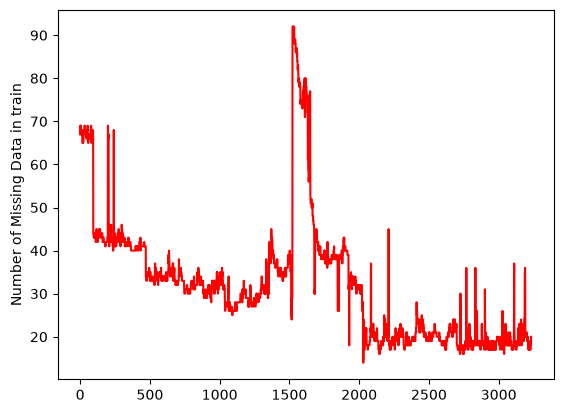

In [32]:
# Same plot as before of train to explore

missing_by_date_train = X_train.drop(columns=['County', 'Station_Name', 'Observation_ID']).isna().sum()

plt.plot(missing_by_date_train.values, color='red')
plt.ylabel("Number of Missing Data in train")
plt.show()

Pipeline

In [33]:
X_num = X_train.drop(columns=['County', 'Station_Name', 'Observation_ID'])
y_num = X_test.drop(columns=['County', 'Station_Name', 'Observation_ID'])

imputer = SimpleImputer(strategy="median")
X_clean = imputer.fit_transform(X_num)
y_clean = imputer.fit_transform(y_num)

baseline_pipe = Pipeline([
    ("model", LinearRegression())
])
baseline_pipe.fit(X_clean, y_clean)

# R-squared
score = baseline_pipe.score(X_clean, y_clean)
print(f"Baseline Model R-squared Score: {score}")

Baseline Model R-squared Score: 0.996750443226927


Group Data Processing:

In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from numpy.lib.stride_tricks import sliding_window_view

# 1. Load datasets
df_avg = pd.read_csv("avg_river_levels.csv")
df_min = pd.read_csv("min_river_levels.csv")
df_max = pd.read_csv("max_river_levels.csv")
df_locs = pd.read_csv("monitoring_locations.csv")

# 2. finalized preprocessing function
def prepare_data(df):
    date_cols = df.columns[3:]
    data = df[date_cols].apply(pd.to_numeric, errors="coerce")
    
    # Scrub impossible sensor errors (|level| > 30m)
    data = data.mask(data.abs() > 30)
    
    # Convert to datetime, sort chronologically, and fill missing calendar days with NaN
    data.columns = pd.to_datetime(date_cols, dayfirst=True)
    data = data.sort_index(axis=1)
    all_dates = pd.date_range(start=data.columns.min(), end=data.columns.max(), freq="D")
    data = data.reindex(columns=all_dates)
    
    # Drop the first 908 dates (Oct 2014 - March 2017) where ~390 stations were inactive
    data = data.iloc[:, 908:]
    
    # Transpose so Dates are rows and Station indices (0-391) are columns
    return data.T

avg = prepare_data(df_avg)
minimum = prepare_data(df_min)
maximum = prepare_data(df_max)

# 3. valid 7-day (+1 target day) window extractor
def get_valid_windows(df):
    numeric_vals = df.to_numpy(float)
    dates = df.index
    
    # 8-day window: Days 1-7 (features) + Day 8 (Next Day target)
    period = sliding_window_view(numeric_vals, 8, axis=0)
    nan_present = ~np.isnan(period).any(axis=2)
    
    ID_name, date_start_name = np.nonzero(nan_present.T)
    valid_periods = period[date_start_name, ID_name, :]
    
    return pd.DataFrame({
        "ID": df.columns[ID_name],
        "Week starting": dates[date_start_name],
        "Day 1": valid_periods[:, 0],
        "Day 2": valid_periods[:, 1],
        "Day 3": valid_periods[:, 2],
        "Day 4": valid_periods[:, 3],
        "Day 5": valid_periods[:, 4],
        "Day 6": valid_periods[:, 5],
        "Day 7": valid_periods[:, 6],
        "Next Day": valid_periods[:, 7]
    })

df_windows = get_valid_windows(avg)
print("Total valid 7-day + next-day windows:", df_windows.shape[0])

Total valid 7-day + next-day windows: 1165020


In [35]:
# ==========================================
# 1. MACIEK'S EXACT 80/20 SPLIT & FLOOD LABELS
# ==========================================

# Check whether given observation is valid across all 3 datasets
valid = avg.notna() & minimum.notna() & maximum.notna()

# Check for 8 consecutive valid days (Days 1-7 features + Day 8 target)
valid_8 = valid.rolling(8, min_periods=8).sum().eq(8)

# Count valid windows for each station
counts = valid_8.sum().sort_values()
print("Total valid 8-day periods:", counts.sum())

# Split approximately 80/20 chronologically based on valid windows
valid_period_sum = valid_8.sum(axis=1).cumsum()
split = (valid_period_sum >= 0.8 * counts.sum()).argmax() + 1

# Define flood events as > 99th percentile of MAXIMUM levels (strictly on training dates)
thresholds = maximum.iloc[:split].quantile(0.99).dropna()

# Identify floods and keep only valid 8-day windows
flood = maximum[thresholds.index] > thresholds
valid_flood = flood.where(valid_8[thresholds.index])

# Stack into 1D target series and drop masked NaNs
y_train = valid_flood.iloc[:split].stack().dropna().astype(int)
y_test = valid_flood.iloc[split:].stack().dropna().astype(int)

print("\nTraining set:")
print(f"Samples: {len(y_train)} | Flood events: {y_train.sum()} | Flood proportion: {100 * y_train.mean():.2f}%")
print("\nTest set:")
print(f"Samples: {len(y_test)} | Flood events: {y_test.sum()} | Flood proportion: {100 * y_test.mean():.2f}%")
print(f"\nActual train proportion: {100 * len(y_train) / (len(y_test) + len(y_train)):.1f}%")


# ==========================================
# 2. BUILD MATCHING FEATURES (RAW & PER-STATION Z-SCORES)
# ==========================================

# Use `maximum` so features match Maciek's flood definition
feat_source = maximum[thresholds.index]

# Calculate per-station mean & std STRICTLY on the training period (:split)
station_mean = feat_source.iloc[:split].mean()
station_std = feat_source.iloc[:split].std().fillna(0) + 1e-8  # avoids NaN or dividing by 0
feat_z = (feat_source - station_mean) / station_std

# Helper function to align the 7 preceding days (Day 1 = t-7 ... Day 7 = t-1) with y_train & y_test
def build_lag_features(df_wide, mask, split_idx):
    train_cols = {}
    test_cols = {}
    for day_num, lag in enumerate(range(7, 0, -1), start=1):
        shifted = df_wide.shift(lag).where(mask)
        train_cols[f"Day {day_num}"] = shifted.iloc[:split_idx].stack().dropna()
        test_cols[f"Day {day_num}"] = shifted.iloc[split_idx:].stack().dropna()
    return pd.DataFrame(train_cols), pd.DataFrame(test_cols)

mask_valid = valid_8[thresholds.index]

# Raw meter features (for your "before Z-scoring" comparison)
X_train, X_test = build_lag_features(feat_source, mask_valid, split)

# Per-station Z-scored features (for your improved SVC models)
X_train_z, X_test_z = build_lag_features(feat_z, mask_valid, split)

print("X_train_z shape:", X_train_z.shape, "| X_test_z shape:", X_test_z.shape)

Total valid 8-day periods: 1164940

Training set:
Samples: 932116 | Flood events: 9517 | Flood proportion: 1.02%

Test set:
Samples: 232824 | Flood events: 2523 | Flood proportion: 1.08%

Actual train proportion: 80.0%
X_train_z shape: (932116, 7) | X_test_z shape: (232824, 7)


In [36]:

# 7-day window down the rows (dates) for all 392 stations at once
windows_7day = sliding_window_view(avg.to_numpy(float), 7, axis=0)

# Check each 7-day window: True if NO days in that 7-day stretch are NaN
is_valid_7day = ~np.isnan(windows_7day).any(axis=2)

# Sum up the True values down the timeline for each of the 392 stations
valid_counts = is_valid_7day.sum(axis=0)

# Attach the station names so the output is easy to read
valid_per_station = pd.Series(valid_counts, index=df_avg["Station_Name"])
print("Valid 7-day periods per station (first 5 stations):")
print(valid_per_station.head())
print("\nSummary across all 392 stations:")
print(valid_per_station.describe())


# Chronological 70/30 Split
# Sort by station ID first, then chronologically by date
df_windows = df_windows.sort_values(["ID", "Week starting"]).reset_index(drop=True)

# Calculate each row's chronological position (from 0.0 to 1.0) within its own station
row_number = df_windows.groupby("ID").cumcount()
total_rows_per_station = df_windows.groupby("ID")["ID"].transform("count")
df_windows["time_pct"] = row_number / total_rows_per_station

# First 70% of each station's timeline goes to train; last 30% goes to test
train_df = df_windows[df_windows["time_pct"] < 0.70].copy()
test_df  = df_windows[df_windows["time_pct"] >= 0.70].copy()


# Define Flood Events (99th Percentile per Station)
# 8. Calculate the 99th percentile water level for EACH station using ONLY train_df
QUANTILE = 0.99  # test 0.95 later
station_thresholds = train_df.groupby("ID")["Next Day"].quantile(QUANTILE)

# Label Flood = 1 if 'Next Day' exceeds that station's threshold, else 0
train_df["Flood"] = (train_df["Next Day"] > train_df["ID"].map(station_thresholds)).astype(int)
test_df["Flood"]  = (test_df["Next Day"] > test_df["ID"].map(station_thresholds)).astype(int)

# Check the sizes and flood proportions in both splits
print(f"\nTrain rows: {len(train_df)} | Test rows: {len(test_df)}")
print(f"Train flood proportion: {train_df['Flood'].mean() * 100:.2f}%")
print(f"Test flood proportion:  {test_df['Flood'].mean() * 100:.2f}%")

Valid 7-day periods per station (first 5 stations):
Station_Name
Bogie, Redcraig               3258
Dee (Grampian), Mar Lodge     3240
Dee (Grampian), Park          3250
Dee (Grampian), Polhollick    3242
Dee (Grampian), Woodend       3238
dtype: int64

Summary across all 392 stations:
count     392.000000
mean     2980.094388
std       615.702530
min       440.000000
25%      3079.750000
50%      3228.000000
75%      3251.000000
max      3459.000000
dtype: float64

Train rows: 815701 | Test rows: 349319
Train flood proportion: 1.02%
Test flood proportion:  1.06%


⁠SVC/SVM/MMC:

Accuracy:  0.9891
Precision: 0.3077
Recall:    0.0016
F1-Score:  0.0032

Classification Report:
              precision    recall  f1-score   support

    No Flood       0.99      1.00      0.99    230301
       Flood       0.31      0.00      0.00      2523

    accuracy                           0.99    232824
   macro avg       0.65      0.50      0.50    232824
weighted avg       0.98      0.99      0.98    232824



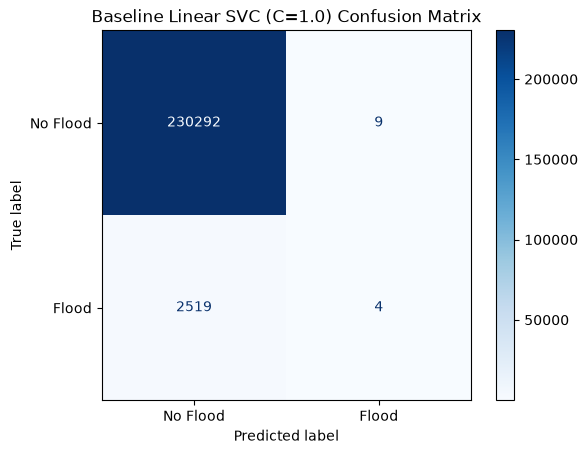

In [37]:


# 2. Build the baseline Linear SVC pipeline (C=1.0)
svc_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("svc", LinearSVC(C=1.0, random_state=42, max_iter=5000))
])


svc_pipe.fit(X_train, y_train)
y_pred = svc_pipe.predict(X_test)

# 4. Print the key metrics
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=["No Flood", "Flood"]))

# 5. Plot the Confusion Matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["No Flood", "Flood"],
    cmap="Blues"
)
plt.title("Baseline Linear SVC (C=1.0) Confusion Matrix")
plt.show()

Tuning C

C = 0.001  | Mean CV F1-Score: 0.0018
C = 0.01   | Mean CV F1-Score: 0.0018
C = 0.1    | Mean CV F1-Score: 0.0018
C = 1.0    | Mean CV F1-Score: 0.0020
C = 10.0   | Mean CV F1-Score: 0.0020
C = 100.0  | Mean CV F1-Score: 0.0020


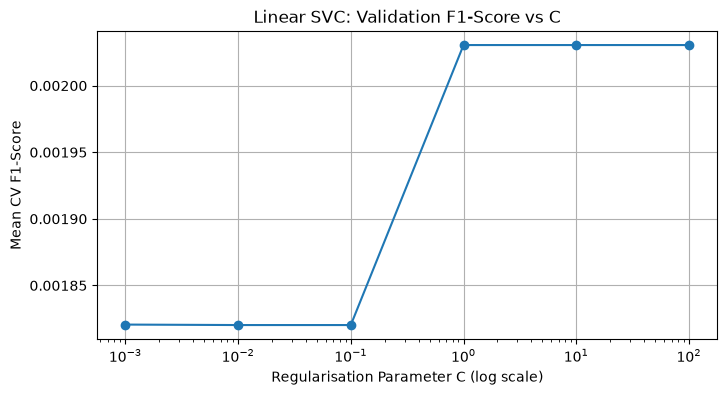

In [38]:
from sklearn.model_selection import TimeSeriesSplit, cross_val_score


# 2. Set up chronological 3-fold cross-validation
tscv = TimeSeriesSplit(n_splits=3)

C_values = [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]
mean_f1_scores = []

for c in C_values:
    pipe = Pipeline([
        ("scaler", StandardScaler()),
        ("svc", LinearSVC(C=c, random_state=42, max_iter=5000))
    ])
    # Evaluate each C using F1-score across the 3 chronological folds
    scores = cross_val_score(pipe, X_train, y_train, cv=tscv, scoring="f1")
    mean_f1_scores.append(scores.mean())
    print(f"C = {c:<6} | Mean CV F1-Score: {scores.mean():.4f}")

# 4. Plot Mean CV F1-Score vs C (using a log scale for C so values are evenly spaced)
plt.figure(figsize=(8, 4))
plt.plot(C_values, mean_f1_scores, marker="o")
plt.xscale("log")
plt.xlabel("Regularisation Parameter C (log scale)")
plt.ylabel("Mean CV F1-Score")
plt.title("Linear SVC: Validation F1-Score vs C")
plt.grid(True)
plt.show()

Including class_weight="balanced", Under-sampling and Over-sampling?

In [39]:

# --- Model 1: LinearSVC with built-in class_weight='balanced' ---
pipe_balanced = Pipeline([
    ("scaler", StandardScaler()),
    ("svc", LinearSVC(C=1.0, class_weight="balanced", random_state=42, max_iter=5000))
])
pipe_balanced.fit(X_train, y_train)
y_pred_bal = pipe_balanced.predict(X_test)

# --- Model 2: Under-sampling + Non-linear RBF SVM ---
pipe_us_rbf = ImbPipeline([
    ("scaler", StandardScaler()),
    ("under", RandomUnderSampler(random_state=42)),
    ("svc", SVC(kernel="rbf", C=1.0, random_state=42))
])
pipe_us_rbf.fit(X_train, y_train)
y_pred_us = pipe_us_rbf.predict(X_test)

# --- Model 3: Over-sampling + LinearSVC ---
pipe_os = ImbPipeline([
    ("scaler", StandardScaler()),
    ("over", RandomOverSampler(random_state=42)),
    ("svc", LinearSVC(C=1.0, random_state=42, max_iter=5000))
])
pipe_os.fit(X_train, y_train)
y_pred_os = pipe_os.predict(X_test)

# --- Compare all 3 models ---
results = []
for name, preds in [
    ("LinearSVC (Balanced Weights)", y_pred_bal),
    ("RBF SVM (Under-sampled)",      y_pred_us),
    ("LinearSVC (Over-sampled)",     y_pred_os),
]:
    results.append({
        "Model": name,
        "Precision": precision_score(y_test, preds),
        "Recall": recall_score(y_test, preds),
        "F1-Score": f1_score(y_test, preds)
    })

display(pd.DataFrame(results))

,Model,Precision,Recall,F1-Score
0,LinearSVC (Balanced Weights),0.042764,0.502180,0.078816
1,RBF SVM (Under-sampled),0.038127,0.565200,0.071436
2,LinearSVC (Over-sampled),0.042675,0.501784,0.078660


Stadarising a flood event?

In [41]:


# 3. Re-run the exact same 3 balanced models on the new Z-score features
# --- Model 1: LinearSVC with balanced class weights ---
pipe_balanced_z = Pipeline([
    ("svc", LinearSVC(C=1.0, class_weight="balanced", random_state=42, max_iter=5000))
])
pipe_balanced_z.fit(X_train_z, y_train)
y_pred_bal_z = pipe_balanced_z.predict(X_test_z)

# --- Model 2: Under-sampling + Non-linear RBF SVM ---
pipe_us_rbf_z = ImbPipeline([
    ("under", RandomUnderSampler(random_state=42)),
    ("svc", SVC(kernel="rbf", C=1.0, random_state=42))
])
pipe_us_rbf_z.fit(X_train_z, y_train)
y_pred_us_z = pipe_us_rbf_z.predict(X_test_z)

# --- Model 3: Over-sampling + LinearSVC ---
pipe_os_z = ImbPipeline([
    ("over", RandomOverSampler(random_state=42)),
    ("svc", LinearSVC(C=1.0, random_state=42, max_iter=5000))
])
pipe_os_z.fit(X_train_z, y_train)
y_pred_os_z = pipe_os_z.predict(X_test_z)

# 4. Compare all 3 models
results_z = []
for name, preds in [
    ("LinearSVC (Balanced Weights + Z-score)", y_pred_bal_z),
    ("RBF SVM (Under-sampled + Z-score)",      y_pred_us_z),
    ("LinearSVC (Over-sampled + Z-score)",     y_pred_os_z),
]:
    results_z.append({
        "Model": name,
        "Precision": precision_score(y_test, preds),
        "Recall": recall_score(y_test, preds),
        "F1-Score": f1_score(y_test, preds)
    })

display(pd.DataFrame(results_z))

,Model,Precision,Recall,F1-Score
0,LinearSVC (Balanced Weights + Z-score),0.066812,0.767737,0.122926
1,RBF SVM (Under-sampled + Z-score),0.059178,0.812921,0.110325
2,LinearSVC (Over-sampled + Z-score),0.066802,0.767737,0.122910


Validation-selected Optimal Threshold (Max F1): 0.1170
Test ROC-AUC Score:          0.8819
Test Average Precision (AP): 0.3282


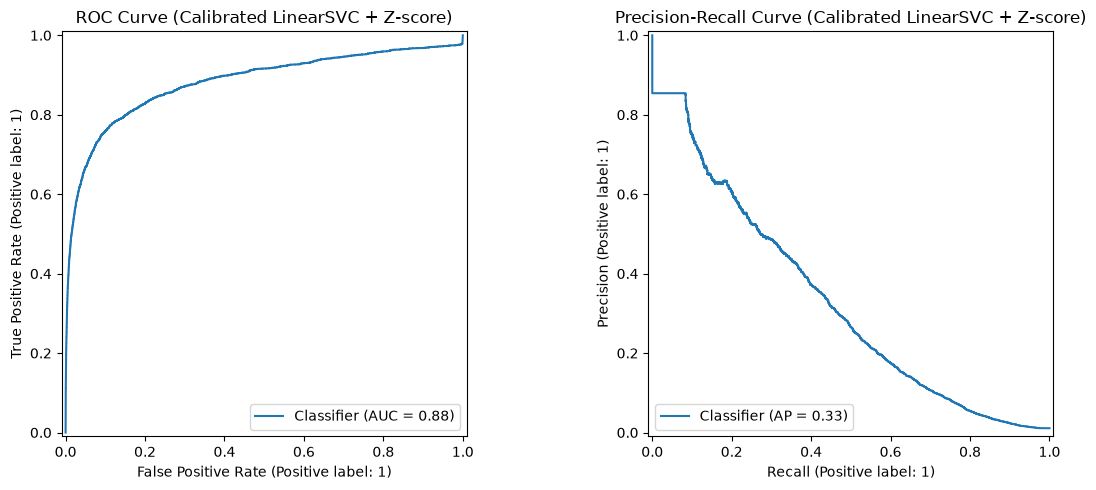

,Model / Threshold,Accuracy,Precision,Recall,F1-Score
0,Group Baseline (Always No Flood),0.989163,0.000000,0.000000,0.000000
1,Threshold = 0.05 (High Recall),0.976927,0.240481,0.523187,0.329506
2,Threshold = 0.10,0.986187,0.371809,0.398335,0.384615
3,Val-Optimal Threshold (0.117),0.987407,0.410660,0.372572,0.390690
4,Threshold = 0.25,0.989645,0.553640,0.229092,0.324082
5,Default Threshold (0.50),0.989876,0.667339,0.131193,0.219278


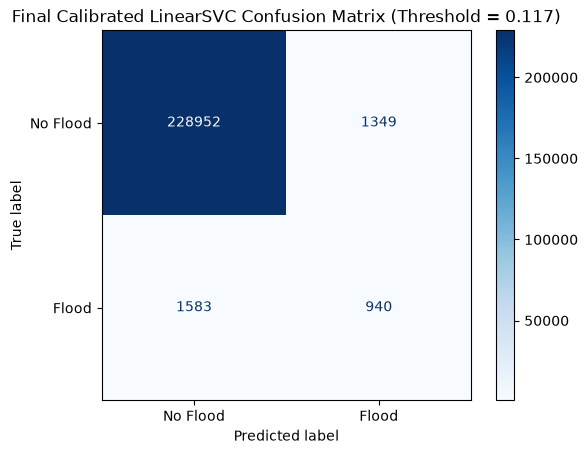

,Feature,Weight
0,Day 1,0.004183
1,Day 2,-0.001426
2,Day 3,-0.002688
3,Day 4,-0.001273
4,Day 5,0.003063
5,Day 6,-0.021448
6,Day 7,0.090667


In [42]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (
    PrecisionRecallDisplay,
    RocCurveDisplay,
    precision_recall_curve,
    roc_auc_score,
    average_precision_score,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# 1. Tune probability threshold using a chronological validation slice inside X_train_z (prevents test leakage)
val_cut = int(0.8 * len(X_train_z))
X_tr, y_tr = X_train_z.iloc[:val_cut], y_train.iloc[:val_cut]
X_val, y_val = X_train_z.iloc[val_cut:], y_train.iloc[val_cut:]

cal_val = CalibratedClassifierCV(
    LinearSVC(C=1.0, random_state=42, max_iter=5000),
    method="sigmoid",  # Platt scaling
    cv=3
)
cal_val.fit(X_tr, y_tr)
val_probs = cal_val.predict_proba(X_val)[:, 1]

# Find the threshold that maximizes F1 on the validation slice
val_prec, val_rec, val_thresh = precision_recall_curve(y_val, val_probs)
val_f1 = 2 * (val_prec[:-1] * val_rec[:-1]) / (val_prec[:-1] + val_rec[:-1] + 1e-10)
best_thresh = val_thresh[np.argmax(val_f1)]
print(f"Validation-selected Optimal Threshold (Max F1): {best_thresh:.4f}")

# 2. Refit final Calibrated LinearSVC on the FULL training set (X_train_z, y_train)
final_svc = CalibratedClassifierCV(
    LinearSVC(C=1.0, random_state=42, max_iter=5000),
    method="sigmoid",
    cv=3
)
final_svc.fit(X_train_z, y_train)

# 3. Evaluate ranking ability on the untouched test set
y_probs = final_svc.predict_proba(X_test_z)[:, 1]
print(f"Test ROC-AUC Score:          {roc_auc_score(y_test, y_probs):.4f}")
print(f"Test Average Precision (AP): {average_precision_score(y_test, y_probs):.4f}")

# 4. Plot ROC Curve and Precision-Recall Curve side-by-side
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
RocCurveDisplay.from_predictions(y_test, y_probs, ax=axes[0])
axes[0].set_title("ROC Curve (Calibrated LinearSVC + Z-score)")

PrecisionRecallDisplay.from_predictions(y_test, y_probs, ax=axes[1])
axes[1].set_title("Precision-Recall Curve (Calibrated LinearSVC + Z-score)")
plt.tight_layout()
plt.show()

# 5. Compare Group Baseline ("Always No Flood") vs candidate thresholds on Test Set
thresh_results = [{
    "Model / Threshold": "Group Baseline (Always No Flood)",
    "Accuracy": accuracy_score(y_test, np.zeros_like(y_test)),
    "Precision": 0.0,
    "Recall": 0.0,
    "F1-Score": 0.0
}]

for label, t in [
    ("Threshold = 0.05 (High Recall)", 0.05),
    ("Threshold = 0.10", 0.10),
    (f"Val-Optimal Threshold ({best_thresh:.3f})", best_thresh),
    ("Threshold = 0.25", 0.25),
    ("Default Threshold (0.50)", 0.50),
]:
    preds_t = (y_probs >= t).astype(int)
    thresh_results.append({
        "Model / Threshold": label,
        "Accuracy": accuracy_score(y_test, preds_t),
        "Precision": precision_score(y_test, preds_t, zero_division=0),
        "Recall": recall_score(y_test, preds_t),
        "F1-Score": f1_score(y_test, preds_t)
    })

display(pd.DataFrame(thresh_results))

# 6. Final Confusion Matrix at the validation-optimal threshold
y_pred_final = (y_probs >= best_thresh).astype(int)
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_final,
    display_labels=["No Flood", "Flood"],
    cmap="Blues"
)
plt.title(f"Final Calibrated LinearSVC Confusion Matrix (Threshold = {best_thresh:.3f})")
plt.show()

# 7. Average feature weights across the 3 calibrated folds (for interpretation)
avg_coefs = np.mean([est.estimator.coef_[0] for est in final_svc.calibrated_classifiers_], axis=0)
coef_df = pd.DataFrame({"Feature": X_train_z.columns, "Weight": avg_coefs})
display(coef_df)

## Problem Setup & Data Split:

Using the cleaned dataset (first 908 inactive days dropped, extreme sensor errors > 30m removed), we extracted 1,164,940 valid consecutive 8-day windows (Days 1–7 as input features, Day 8 as the target).

We used a chronological 80/20 split to prevent future weather data from leaking into training (932,116 training samples; 232,824 test samples).

A flood is defined as Day 8's maximum water level exceeding a station's 99th percentile, calculated strictly on the training set (1.02% flood rate in train; 1.08% in test).

Because floods are rare (~1%), our baseline always predicts "No Flood". On the test set, this achieves 98.92% accuracy but 0.000 Precision, 0.000 Recall, and 0.000 F1-score, showing why accuracy is misleading on imbalanced data.

## Model Choice & Early Exploration

Why LinearSVC? With ~932,000 training rows, a standard non-linear SVC scales poorly and is too slow to run on the full dataset. LinearSVC trains in seconds on all rows and outputs interpretable feature weights.

Initial LinearSVC (Raw Meters, C=1.0): Using StandardScaler in a pipeline, the untuned model achieved 98.91% accuracy, but caught only 4 out of 2,523 floods (Recall = 0.0016, F1 = 0.0032).   

Tuning C (0.001 to 100.0): Using 3-fold TimeSeriesSplit cross-validation (preserving time order), the mean CV F1-score flatlined at 0.0018–0.0020 across all values of C. This showed that regularisation alone cannot fix a 99:1 class imbalance.

Class Balancing & Resampling (Raw Meters): To stop the model ignoring floods, we compared class_weight="balanced", over-sampling (RandomOverSampler), and under-sampling (RandomUnderSampler with a non-linear RBF SVM): 

Recall jumped to 50%–57%, but Precision stayed very low (3.8%–4.3%, F1 = 0.071–0.079).   

class_weight="balanced" matched over-sampling (0.0788 vs 0.0787 F1) without duplicating rows.   

Why Precision was so low: Raw water levels in metres cannot be fairly compared across different rivers (a 1.0m reading can be a major flood for a shallow stream but a calm day for a deep river).

# Feature Engineering: Per-Station Z-Scoring

To fix the river-depth problem, we standardised Days 1–7 per station using each station's training-set mean and standard deviation (preventing data leakage).

Every input feature now measures how many standard deviations a river is above or below its own normal level.

Impact: Every balanced model improved immediately on the test set:   

LinearSVC (Balanced Weights + Z-score): Recall jumped from 50.2% to 76.8%, Precision rose to 6.7%, and F1 increased from 0.079 to 0.123.   

RBF SVM (Under-sampled + Z-score): Reached higher Recall (81.3%) but lower Precision (5.9%) and lower F1 (0.110) than LinearSVC, while discarding ~98% of non-flood training data. 
We therefore rejected the under-sampled RBF SVM and over-sampling, and selected LinearSVC with per-station Z-scores as our core model.

# Final Model: Probability Calibration & Threshold Tuning

Why we dropped 50/50 resampling: Training on balanced classes made the model assume floods happen 50% of the time, triggering too many false alarms (~6.7% precision).   
Final Pipeline: We trained LinearSVC (C=1.0) on the unresampled per-station Z-scored training data so it learned the true ~1% flood rate, and wrapped it in CalibratedClassifierCV(method="sigmoid", cv=3) (Platt scaling) to output flood probabilities.
Validation (No Test Leakage): We held out the final 20% of the training period chronologically as a validation slice to pick the F1-optimal probability threshold (0.117), then refitted on the full training set and evaluated once on the untouched test set.

# Final Test Results & Baseline Comparison
Ranking Performance (ROC & PR Curves): The final model achieved a ROC-AUC of 0.8819 (correctly ranking a random flood day above a normal day 88.2% of the time) and an Average Precision (AP) of 0.3282 (~30x better than the 0.011 random baseline on this 1.08% flood rate).

Confusion Matrix (Threshold = 0.117): The model correctly identified 940 floods (up from 4 in the untuned baseline), with 1,349 false alarms out of 230,301 normal days (<0.6% false positive rate) and 1,583 missed floods.

Policy Flexibility: For the Scottish Government, the threshold can be adjusted depending on operational priorities—for example, lowering the cutoff to 0.05 catches 52.3% of floods while still keeping 1 in 4 alerts accurate (24.0% precision).

# Key Findings, Interpretation & Limitations (Notes for the Discussion Section)

What drives flood predictions (Feature Weights):   
Day 7 (+0.0907): Yesterday's standardised water level is by far the strongest positive predictor of a flood today.   
Day 6 (-0.0214): The negative weight on Day 6 alongside the strong positive weight on Day 7 means the model learned to detect rapidly rising water levels (a sharp upward surge over the last 48 hours increases flood risk, whereas a high level that is already falling carries lower risk).   
Days 1–5 (-0.0027 to +0.0042): Water levels from 3 to 7 days earlier add almost no predictive value once the last two days are known. 

# Main Limitation

The model relies solely on historical river levels with no rainfall, snowmelt, or weather forecast data. Sudden overnight storms can cause flash floods with no warning signal in the previous 7 days. Adding Met Office rainfall forecasts and station cluster labels (e.g., separating tidal vs. non-tidal rivers) would be the next step.
